# MaintAI — Adaptation légère (LoRA / QLoRA) d'un petit LLM sur MaintIE

Extraction d'information sur des textes de maintenance industrielle : comparaison du modèle de base (zero-shot, few-shot) et du modèle adapté (LoRA, QLoRA), sur deux tailles de modèle.

**Réglages Kaggle :** Accelerator = **GPU T4 x2** · Internet = **On** · *Add Input* → le dataset `maintai`.

**Conseil :** lancez d'abord tout avec `RAPIDE = True` (≈ 10 min) pour vérifier la chaîne, puis remettez `RAPIDE = False` et faites **Save Version → Save & Run All**. Chaque étape déjà faite est sautée : si la session coupe, relancez simplement.

## Réglages

In [11]:
M05 = 'Qwen/Qwen2.5-0.5B-Instruct'   # petit modèle
M15 = 'Qwen/Qwen2.5-1.5B-Instruct'   # modèle moyen
RAPIDE = False       # True = test express : 20 textes de test, 80 d'entraînement, 1 epoch
FAIRE_15B = True     # expériences sur le 1.5B
FAIRE_QLORA = True   # QLoRA sur le 1.5B (nécessite un GPU)

## 0. Installation et vérification

In [12]:
import os, glob, shutil, json
from pathlib import Path
os.environ['CUDA_VISIBLE_DEVICES'] = '0'   # un seul GPU : mesures de mémoire justes
if Path('/kaggle/input').exists():
    get_ipython().system("pip install -q 'peft>=0.12' bitsandbytes")
    src = os.path.dirname(glob.glob('/kaggle/input/**/infer.py', recursive=True)[0])
    shutil.copytree(src, '/kaggle/working/maintai', dirs_exist_ok=True)
    os.chdir('/kaggle/working/maintai')
    get_ipython().system('nvidia-smi --query-gpu=name,memory.total --format=csv')
print('Dossier de travail :', os.getcwd())
for s in ('train', 'val', 'test'):
    print(s, sum(1 for _ in open(f'data/{s}.jsonl')), 'textes')

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
Dossier de travail : /kaggle/working/maintai
train 860 textes
val 107 textes
test 108 textes


In [13]:
# Exécute une commande, s'arrête en cas d'erreur, et saute l'étape si sa sortie existe déjà
def etape(sortie, cmd):
    if sortie and Path(sortie).exists():
        print('déjà fait :', sortie)
        return
    print('$', cmd)
    ip = get_ipython()
    ip.system(cmd)
    if ip.user_ns.get('_exit_code', 0):
        raise RuntimeError(f'Échec de : {cmd}')

TEST, OPTS_TRAIN = 'data/test.jsonl', ''
if RAPIDE:
    TEST, OPTS_TRAIN = 'data/test_rapide.jsonl', '--limit 80 --epochs 1'
    with open('data/test.jsonl') as f, open(TEST, 'w') as g:
        g.writelines(f.readlines()[:20])
# Les sorties d'un test rapide ne doivent jamais se mélanger à celles des vraies expériences
mode, marque = ('rapide' if RAPIDE else 'complet'), Path('results/.mode')
if marque.exists() and marque.read_text() != mode:
    for d in ('results', 'runs', 'figures'):
        shutil.rmtree(d, ignore_errors=True)
    print('Sorties du mode précédent effacées.')
Path('results').mkdir(exist_ok=True)
marque.write_text(mode)
print('Mode :', mode, '· jeu de test :', TEST)

Mode : complet · jeu de test : data/test.jsonl


In [14]:
# Vérification : 3 textes avec le modèle de base en 5-shot (≈ 2 min)
etape(None, f'python infer.py --model {M05} --test {TEST} --shots 5 --limit 3 --out results/verif.jsonl')

$ python infer.py --model Qwen/Qwen2.5-0.5B-Instruct --test data/test.jsonl --shots 5 --limit 3 --out results/verif.jsonl
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 628.27it/s]
[1/3] '<num> hour mechanical inspection carry roller number <num> right hand <id>' -> {"equipements": ["mechanical inspection", "carry roller"], "symptomes": [], "actions": ["inspect"], "proprietes": [{"id": "<id>", "number": "<num>", "
[2/3] '<id> - Tele-Remote installation and tune' -> {"equipements": [], "symptomes": [], "actions": ["install"], "proprietes": []}
[3/3] '<id> - rectify low power fault' -> {"equipements": [], "symptomes": ["low power fault"], "actions": ["rectify"], "proprietes": []}
{
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "adapter": null,
  "shots": 5,
  "load_4bit": false,
  "n": 3,
  "latence_moyenne_s": 1.4334,
  "memoire_gpu_max_go": 1.037
}


In [16]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 1. Qwen2.5-0.5B : LoRA d'abord, puis les baselines

In [17]:
etape('runs/lora05/train_stats.json', f'python train_lora.py --model {M05} {OPTS_TRAIN} --out runs/lora05')
etape('results/lora05.jsonl', f'python infer.py --model {M05} --adapter runs/lora05 --test {TEST} --shots 0 --out results/lora05.jsonl')

$ python train_lora.py --model Qwen/Qwen2.5-0.5B-Instruct  --out runs/lora05
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 602.69it/s]
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
epoch 1 step 20/108 loss 0.2266
epoch 1 step 40/108 loss 0.1528
epoch 1 step 60/108 loss 0.1202
epoch 1 step 80/108 loss 0.1045
epoch 1 step 100/108 loss 0.0923
{'epoch': 1, 'train_loss': 0.0891, 'val_loss': 0.0432}
epoch 2 step 20/108 loss 0.0129
epoch 2 step 40/108 loss 0.0159
epoch 2 step 60/108 loss 0.0178
epoch 2 step 80/108 loss 0.0168
epoch 2 step 100/108 loss 0.0158
{'epoch': 2, 'train_loss': 0.0158, 'val_loss': 0.032}
epoch 3 step 20/108 loss 0.0043
epoch 3 step 40/108 loss 0.0046
epoch 3 step 60/108 loss 0.0042
epoch 3 step 80/108 loss 0.0041
epoch 3 step 100/108 loss 0.0040
{'ep

In [18]:
etape('results/base05_zs.jsonl', f'python infer.py --model {M05} --test {TEST} --shots 0 --out results/base05_zs.jsonl')
etape('results/base05_fs.jsonl', f'python infer.py --model {M05} --test {TEST} --shots 5 --out results/base05_fs.jsonl')

$ python infer.py --model Qwen/Qwen2.5-0.5B-Instruct --test data/test.jsonl --shots 0 --out results/base05_zs.jsonl
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 595.65it/s]
[1/108] '<num> hour mechanical inspection carry roller number <num> right hand <id>' -> ```json
{
  "equipements": [
    {
      "name": "<id>",
      "type": "mechanical",
      "description": "inspection tool"
    }
  ],
  "symptomes": 
[2/108] '<id> - Tele-Remote installation and tune' -> ```json
{
  "equipements": [
    {
      "type": "equipment",
      "name": "Tele-Remote installation and tune"
    }
  ],
  "symptomes": [
    {
    
[3/108] '<id> - rectify low power fault' -> [
  ["rectify"],
  ["low power"]
]
[20/108] '<id> bent belly plate' -> [[
<bent belly plate></bent belly plate>]
[40/108] '<id> - fuel cap is missing' -> ```json
{
  "equipements": [
    {
      "part": "fuel cap"
    }
  ],
  "symptomes": [],
  "act

## 2. Qwen2.5-1.5B : LoRA, baselines, puis QLoRA

In [19]:
if FAIRE_15B:
    etape('runs/lora15/train_stats.json', f'python train_lora.py --model {M15} {OPTS_TRAIN} --out runs/lora15')
    etape('results/lora15.jsonl', f'python infer.py --model {M15} --adapter runs/lora15 --test {TEST} --shots 0 --out results/lora15.jsonl')
    etape('results/base15_zs.jsonl', f'python infer.py --model {M15} --test {TEST} --shots 0 --out results/base15_zs.jsonl')
    etape('results/base15_fs.jsonl', f'python infer.py --model {M15} --test {TEST} --shots 5 --out results/base15_fs.jsonl')

$ python train_lora.py --model Qwen/Qwen2.5-1.5B-Instruct  --out runs/lora15
config.json: 100%|█████████████████████████████| 660/660 [00:00<00:00, 3.92MB/s]
tokenizer_config.json: 100%|███████████████| 7.30k/7.30k [00:00<00:00, 26.6MB/s]
vocab.json: 100%|██████████████████████████| 2.78M/2.78M [00:00<00:00, 51.2MB/s]
merges.txt: 100%|███████████████████████████| 1.67M/1.67M [00:00<00:00, 121MB/s]
tokenizer.json: 100%|███████████████████████| 7.03M/7.03M [00:00<00:00, 142MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

model.safetensors: downloading bytes:                       |  0.00B            
model.safetensors: downloading bytes: ▍                     | 65.7MB, 5.36MB/s  
model.safetensors: downloading bytes: ▉                     |  138MB, 10.4MB/s  
model.safetensors: downloading bytes: █▏                    |  164MB, 12.9MB/s  
model.safetensors: reconstructing file:   6%|▎     |  176MB / 3.09GB, 12.9MB/s  
model.safetensors: downloading bytes: █████████

In [20]:
# QLoRA : base quantifiée en 4 bits à l'entraînement ET à l'inférence (mêmes réglages que LoRA)
if FAIRE_15B and FAIRE_QLORA:
    etape('runs/qlora15/train_stats.json', f'python train_lora.py --model {M15} --qlora {OPTS_TRAIN} --out runs/qlora15')
    etape('results/qlora15.jsonl', f'python infer.py --model {M15} --adapter runs/qlora15 --load-4bit --test {TEST} --shots 0 --out results/qlora15.jsonl')

$ python train_lora.py --model Qwen/Qwen2.5-1.5B-Instruct --qlora  --out runs/qlora15
Loading weights: 100%|███████████████████████| 338/338 [00:01<00:00, 299.57it/s]
trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
epoch 1 step 20/108 loss 0.1854
epoch 1 step 40/108 loss 0.1234
epoch 1 step 60/108 loss 0.0974
epoch 1 step 80/108 loss 0.0817
epoch 1 step 100/108 loss 0.07

## 3. Évaluation, comparaisons, erreurs, figures

In [21]:
CONFIGS = ['base05_zs', 'base05_fs', 'lora05', 'base15_zs', 'base15_fs', 'lora15', 'qlora15']
for c in CONFIGS:
    if Path(f'results/{c}.jsonl').exists():
        etape(None, f'python evaluate.py --gold {TEST} --pred results/{c}.jsonl --out results/{c}_metrics.json > /dev/null')
etape(None, 'python summarize.py --out results/tableau.csv')

$ python evaluate.py --gold data/test.jsonl --pred results/base05_zs.jsonl --out results/base05_zs_metrics.json > /dev/null
$ python evaluate.py --gold data/test.jsonl --pred results/base05_fs.jsonl --out results/base05_fs_metrics.json > /dev/null
$ python evaluate.py --gold data/test.jsonl --pred results/lora05.jsonl --out results/lora05_metrics.json > /dev/null
$ python evaluate.py --gold data/test.jsonl --pred results/base15_zs.jsonl --out results/base15_zs_metrics.json > /dev/null
$ python evaluate.py --gold data/test.jsonl --pred results/base15_fs.jsonl --out results/base15_fs_metrics.json > /dev/null
$ python evaluate.py --gold data/test.jsonl --pred results/lora15.jsonl --out results/lora15_metrics.json > /dev/null
$ python evaluate.py --gold data/test.jsonl --pred results/qlora15.jsonl --out results/qlora15_metrics.json > /dev/null
$ python summarize.py --out results/tableau.csv
configuration | F1_global | JSON_valide | inventions | latence_s | pct_params_entraines | temps_entr

In [22]:
import pandas as pd
pd.set_option('display.width', 200)
pd.read_csv('results/tableau.csv')

,configuration,F1_global,F1_ic95_bas,F1_ic95_haut,precision,rappel,F1_equipements,F1_symptomes,F1_actions,F1_proprietes,JSON_valide,inventions,exact_match,latence_s,mem_inference_Go,pct_params_entraines,temps_entrainement_min,mem_entrainement_Go
0,base05_zs,0.0063,0.0000,0.0191,0.0625,0.0033,0.0116,0.0000,0.0000,0.0000,0.0185,0.7500,0.0000,1.1968,1.008,0.000,0.00,NaN
1,base05_fs,0.5306,0.4757,0.5852,0.5417,0.5200,0.4621,0.6833,0.5574,0.0000,0.9907,0.1146,0.1204,1.0337,1.037,0.000,0.00,NaN
2,lora05,0.8955,0.8542,0.9375,0.8911,0.9000,0.8798,0.8704,0.9645,0.7692,1.0000,0.0000,0.7870,2.0620,1.047,1.750,3.18,4.153
3,base15_zs,0.2657,0.1927,0.3373,0.5354,0.1767,0.2609,0.4211,0.1348,0.0000,0.3426,0.2525,0.0648,2.2839,3.113,0.000,0.00,NaN
4,base15_fs,0.5534,0.4966,0.6078,0.5830,0.5267,0.4238,0.6761,0.7114,0.0000,1.0000,0.1292,0.2222,1.2396,3.147,0.000,0.00,NaN
5,lora15,0.9015,0.8645,0.9361,0.9030,0.9000,0.8680,0.9259,0.9781,0.7692,1.0000,0.0000,0.7685,2.4466,3.197,1.182,7.50,6.444
6,qlora15,0.9052,0.8681,0.9388,0.9037,0.9067,0.8772,0.9346,0.9710,0.7143,1.0000,0.0000,0.7685,3.2544,1.280,1.182,9.78,5.583


In [23]:
# LoRA améliore-t-il significativement le modèle de base ? (bootstrap apparié)
etape(None, f'python compare.py --gold {TEST}')

$ python compare.py --gold data/test.jsonl
 base05_zs -> lora05   ΔF1 = +0.889 [+0.847 ; +0.930]  p = 0.000  significatif : oui
 base05_fs -> lora05   ΔF1 = +0.365 [+0.311 ; +0.422]  p = 0.000  significatif : oui
 base15_zs -> lora15   ΔF1 = +0.636 [+0.560 ; +0.715]  p = 0.000  significatif : oui
 base15_fs -> lora15   ΔF1 = +0.348 [+0.283 ; +0.411]  p = 0.000  significatif : oui
    lora05 -> lora15   ΔF1 = +0.006 [-0.022 ; +0.036]  p = 0.725  significatif : non
 base15_fs -> lora05   ΔF1 = +0.342 [+0.283 ; +0.407]  p = 0.000  significatif : oui
    lora15 -> qlora15  ΔF1 = +0.004 [-0.020 ; +0.029]  p = 0.772  significatif : non

Tableau : results/comparaisons.csv


In [24]:
etape(None, f'python error_analysis.py --gold {TEST}')

$ python error_analysis.py --gold data/test.jsonl
configuration  json_invalid  masque_extra  mauvais_cham     frontiere     invention  faux_positif         oubli   total
base05_zs              106             3             0             2             9             1             3     124
base05_fs                1             0            18            54            33            27            47     180
lora05                   0             0             4            24             0             5             6      39
base15_zs               71             0             4            15            25             2            25     142
base15_fs                0             0            19            49            35            10            42     155
lora15                   0             0             4            24             0             1             8      37
qlora15                  0             0             3            25             0             1             6      

$ python make_figures.py
figure : figures/fig1_f1_global.png
figure : figures/fig2_f1_par_champ.png
figure : figures/fig3_couts.png
figure : figures/fig4_pertes.png
figure : figures/fig5_erreurs.png
figures/fig1_f1_global.png


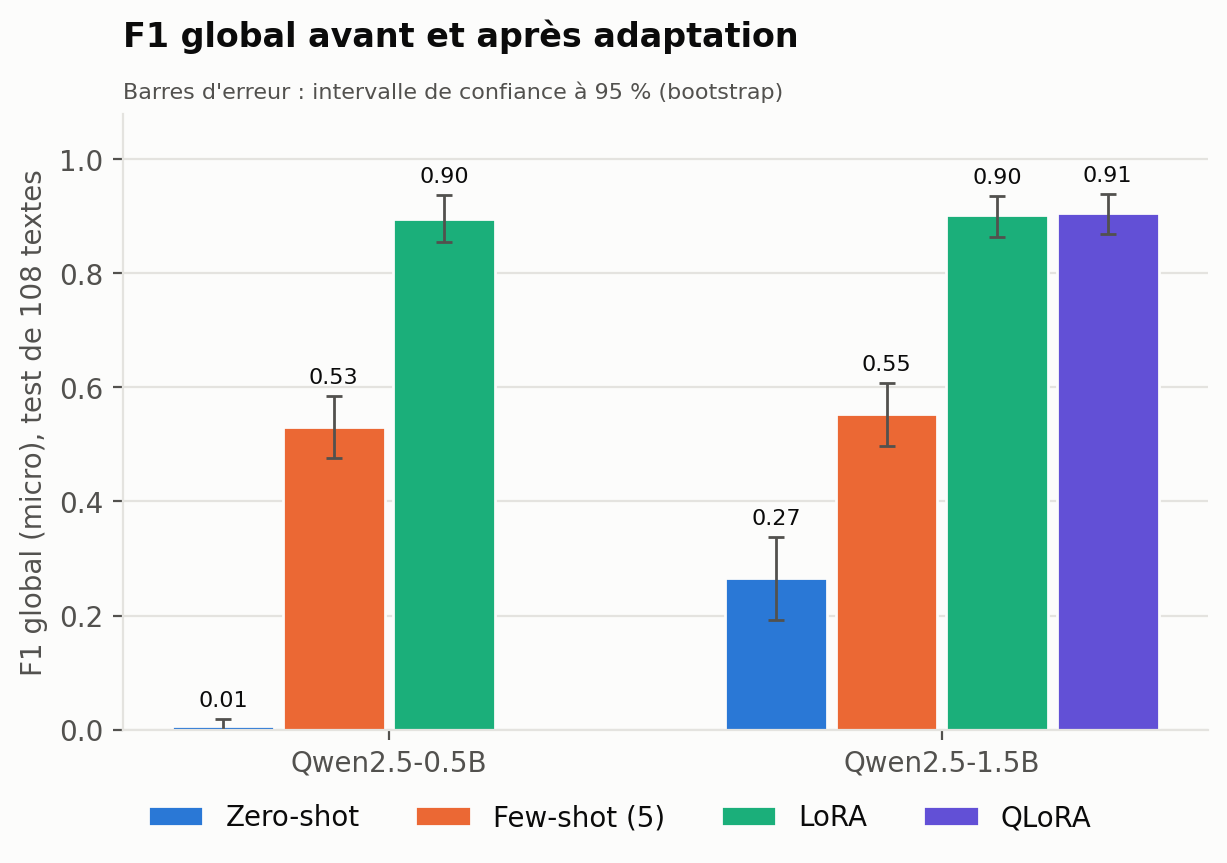

figures/fig2_f1_par_champ.png


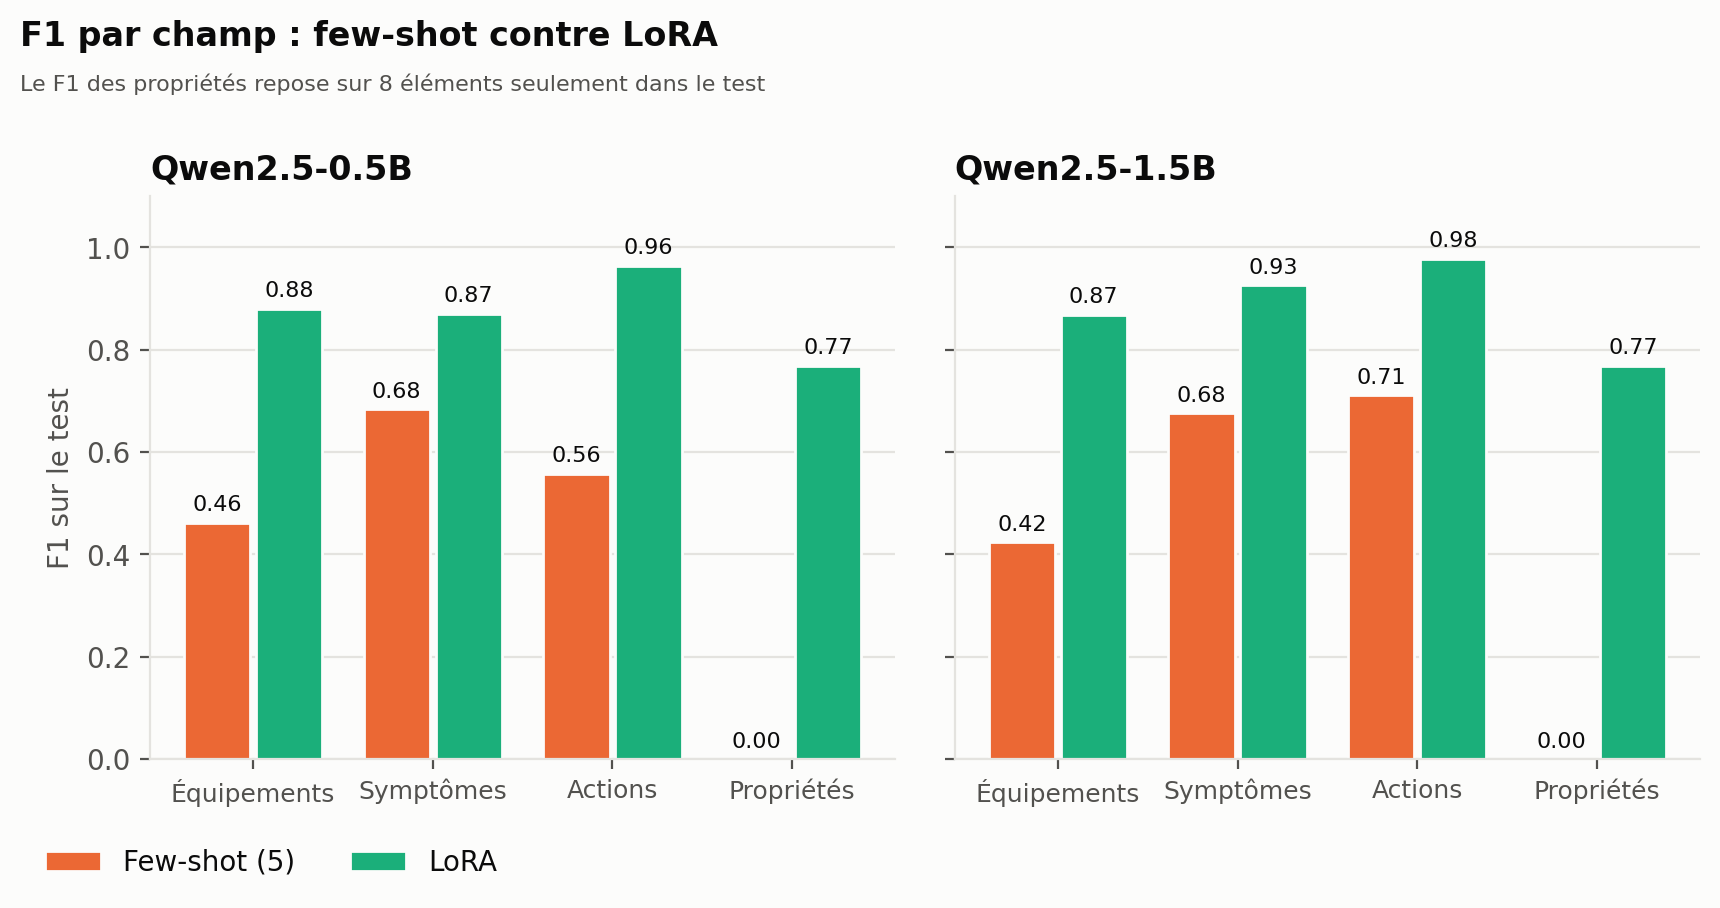

figures/fig3_couts.png


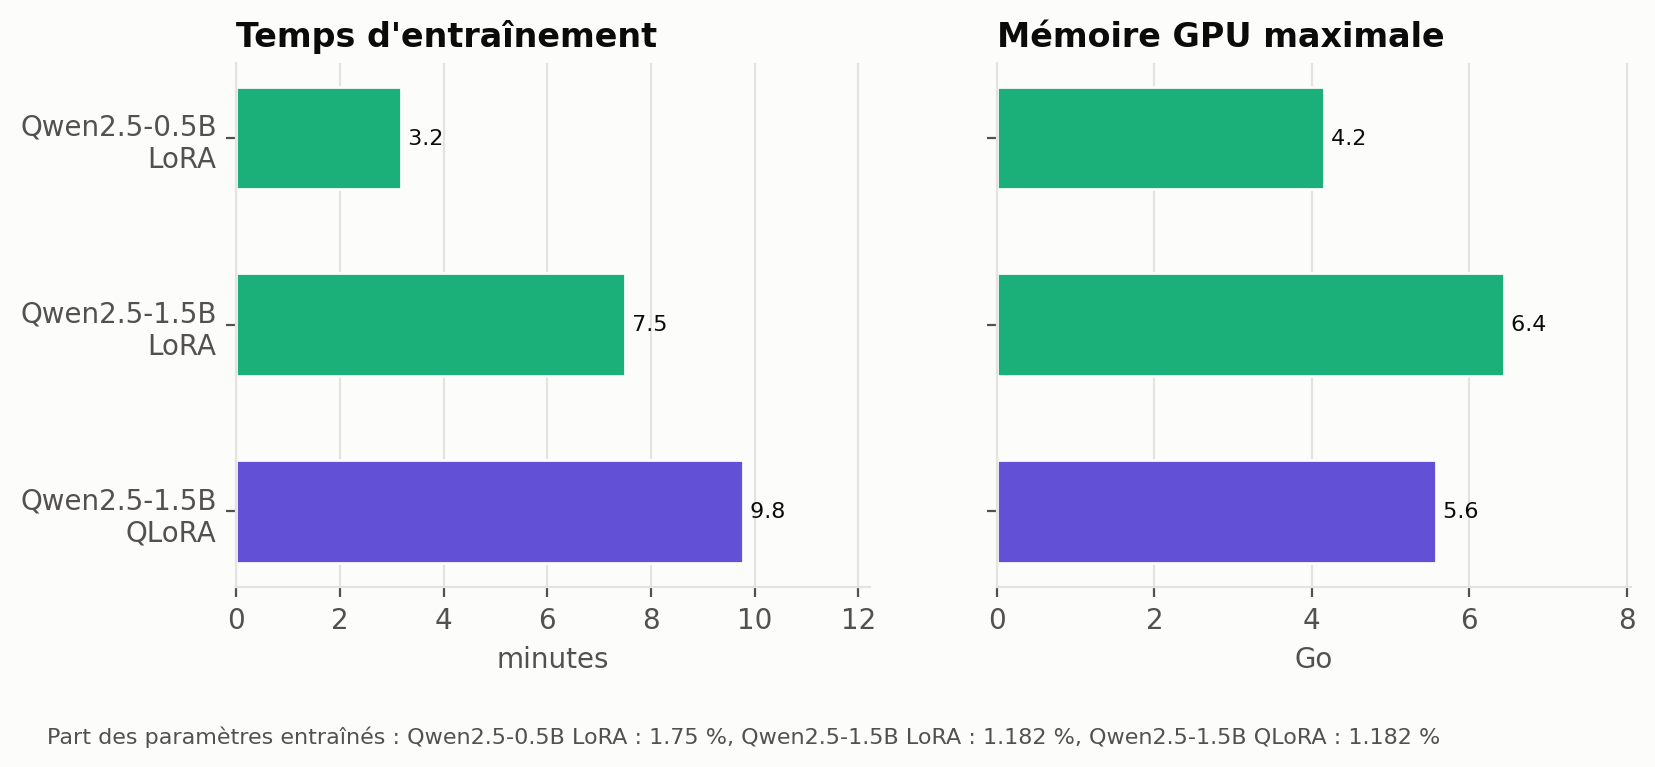

figures/fig4_pertes.png


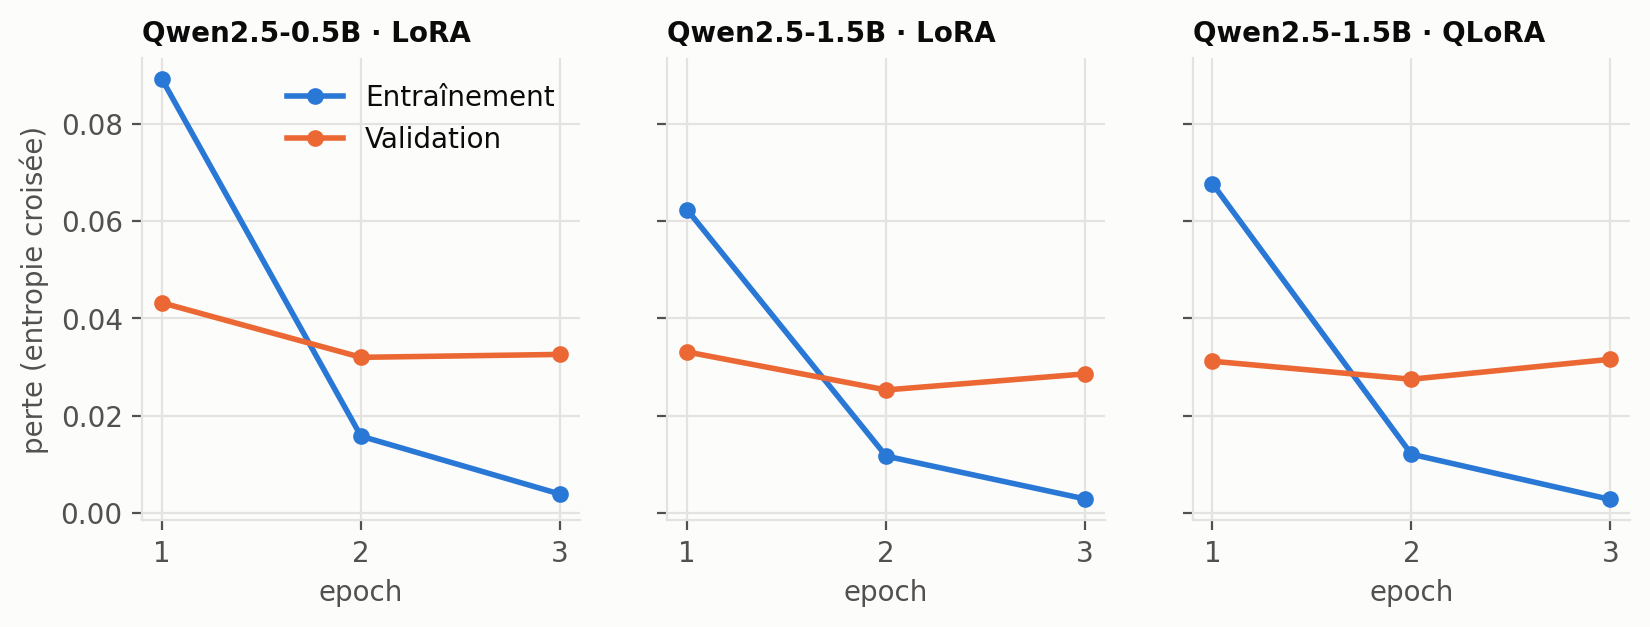

figures/fig5_erreurs.png


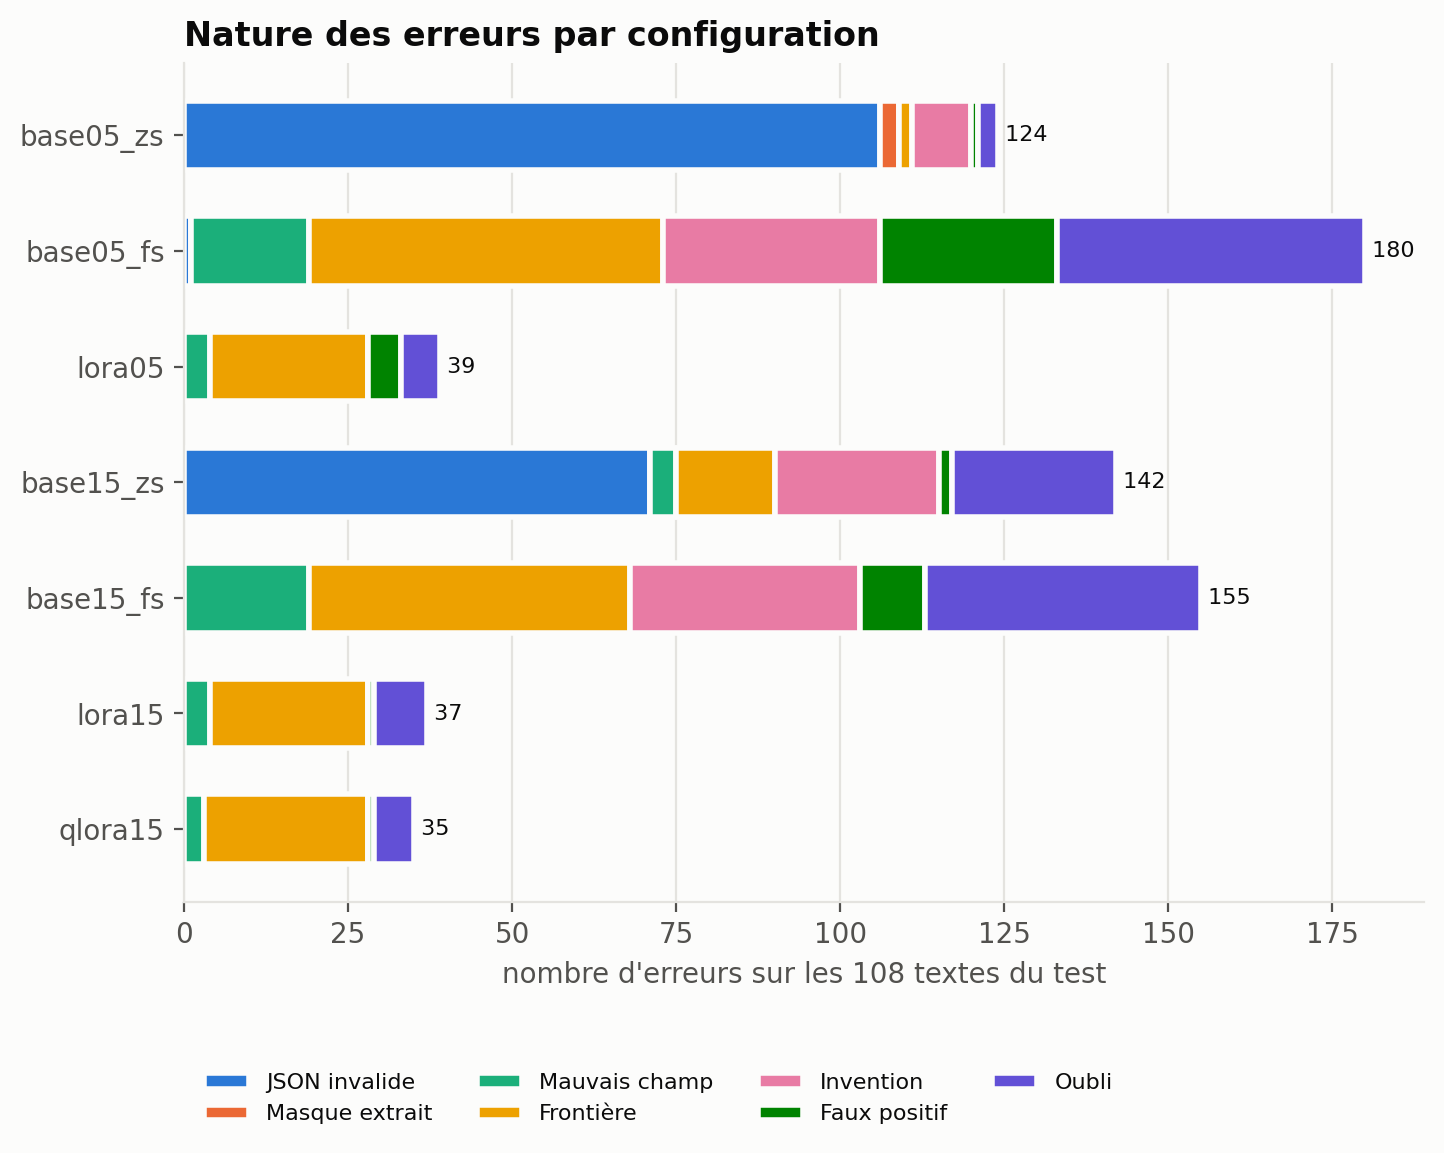

In [25]:
etape(None, 'python make_figures.py')
from IPython.display import Image, display
for f in sorted(glob.glob('figures/*.png')):
    print(f)
    display(Image(f))

In [26]:
# Quelques erreurs de LoRA à lire pour l'analyse qualitative
name = 'lora15' if Path('results/erreurs_lora15.csv').exists() else 'lora05'
pd.read_csv(f'results/erreurs_{name}.csv').groupby('categorie').head(3)

,categorie,champ,element,texte,attendu,sortie_modele
0,mauvais_champ,equipements,cover,<id> - cover steering ball studs,"equipements=['steering', 'ball studs']; action...","{""equipements"": [""cover"", ""steering"", ""ball st..."
1,mauvais_champ,actions,bent,<id> bent belly plate,equipements=['belly plate']; symptomes=['bent'],"{""equipements"": [""belly plate""], ""symptomes"": ..."
2,mauvais_champ,symptomes,noisy,bearing noisy,equipements=['bearing']; proprietes=['noisy'],"{""equipements"": [""bearing""], ""symptomes"": [""no..."
4,frontiere,equipements,boom,<id> - left hand side boom foot crack repair,equipements=['boom foot']; actions=['repair'];...,"{""equipements"": [""boom"", ""foot""], ""symptomes"":..."
5,frontiere,equipements,foot,<id> - left hand side boom foot crack repair,equipements=['boom foot']; actions=['repair'];...,"{""equipements"": [""boom"", ""foot""], ""symptomes"":..."
6,frontiere,equipements,am,<id> - no reception on AM / FM radio,equipements=['AM / FM radio']; symptomes=['no ...,"{""equipements"": [""AM"", ""FM""], ""symptomes"": [""n..."
28,faux_positif,symptomes,large crack,<num> glass window has large crack,equipements=['glass window']; proprietes=['cra...,"{""equipements"": [""glass"", ""window""], ""symptome..."
29,oubli,equipements,<sensitive>,<id> <sensitive> to fit coolant meters,"equipements=['<sensitive>', 'coolant meters'];...","{""equipements"": [""coolant"", ""meters""], ""sympto..."
30,oubli,equipements,<sensitive>,<id> <sensitive> to supply and fit cabin mounts,"equipements=['<sensitive>', 'cabin', 'mounts']...","{""equipements"": [""cabin"", ""mounts""], ""symptome..."
31,oubli,equipements,frame,<id> boilermakers to repair cooler frame,"equipements=['boilermakers', 'cooler', 'frame'...","{""equipements"": [""boilermakers"", ""cooler""], ""s..."


## 4. Sauvegarde
Téléchargez `maintai_sorties.zip` (onglet **Output** après *Save Version*, ou panneau de droite). Il contient les résultats, les tableaux, les figures et les adaptateurs.

In [27]:
etape(None, "rm -f maintai_sorties.zip && zip -qr maintai_sorties.zip results figures runs -x 'runs/*/checkpoint*'")
print(round(os.path.getsize('maintai_sorties.zip') / 1e6, 1), 'Mo')

$ rm -f maintai_sorties.zip && zip -qr maintai_sorties.zip results figures runs -x 'runs/*/checkpoint*'
176.4 Mo
